# 03 – Anwendung: Wer passt besser, als das Modell erwartet? (Aufgabe 2)

**Kernaussage:** Die Passquote zeigt vor allem, *welche* Pässe ein Spieler spielt. Erst der Vergleich mit dem Modell zeigt, *wie gut* er sie spielt. Nach 7 Spielen ist das ein Hinweis für das Video-Scouting, noch kein Urteil.

**Kennzahl – Pässe über Erwartung (PüE) pro 100 Pässe:**

$$\text{PüE}_{100} = 100 \cdot \frac{\text{angekommene Pässe} - \sum \text{xPass}}{\text{Pässe}} = \text{Passquote} - \text{erwartete Passquote}$$

+5 heißt: Von 100 Pässen bringt der Spieler 5 mehr an als ein durchschnittlicher Spieler mit genau denselben Pässen (gleicher Ort, gleiche Richtung, gleiche Höhe, gleiche Situation).


**Grundlage:** xPass des Zonenmodells aus Notebook 02 (`data/vorhersagen_zonen.csv`; jedes Spiel wurde von einem Modell vorhergesagt, das dieses Spiel nicht kannte). Positionen aus den DFL-Metadaten (`auswertung.py`).

**Ablauf:** 1. Warum nicht einfach die Passquote? → 2. Rangliste, fair nur innerhalb der Rolle → 3. Wie belastbar ist das?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from auswertung import ROLLEN, bilanz, hauptrolle, mit_rollen
from passdaten import MATCH_IDS

# xPass je Pass (Notebook 02) und Rolle des Passgebers (DFL-Metadaten)
d = pd.read_csv(ROOT / "data" / "vorhersagen_zonen.csv", dtype={"event_id": str, "player_id": str})
d = mit_rollen(d, MATCH_IDS)
d["hauptrolle"] = d["player_id"].map(hauptrolle(d)).fillna("unbekannt")

# Eine Zeile je Spieler: Pässe, angekommen, erwartet, PüE (Funktion bilanz in auswertung.py)
spieler = bilanz(d, ["player_id", "player", "team", "hauptrolle"]).reset_index()
spieler["passquote"] = 100 * spieler["angekommen"] / spieler["paesse"]       # tatsächlich angekommen (%)
spieler["erwartete_quote"] = 100 * spieler["erwartet"] / spieler["paesse"]   # Mittelwert seiner xPass-Werte (%)

stamm = spieler[spieler["paesse"] >= 50].copy()       # Spieler mit mindestens 50 Pässen
print(f"{len(d)} Pässe, davon {len(stamm)} Spieler mit mindestens 50 Pässen")

5664 Pässe, davon 29 Spieler mit mindestens 50 Pässen


## 1. Die Passquote misst vor allem, welche Pässe ein Spieler spielt

Die **erwartete Passquote** ist der Mittelwert der xPass-Werte eines Spielers, also wie leicht seine Pässe im Schnitt waren. Wer auf der Diagonalen liegt, bringt genau so viele Pässe an, wie bei diesen Pässen zu erwarten ist. Der senkrechte Abstand zur Diagonalen ist die PüE pro 100.

Korrelation zwischen Passquote und erwarteter Passquote: r = 0.92


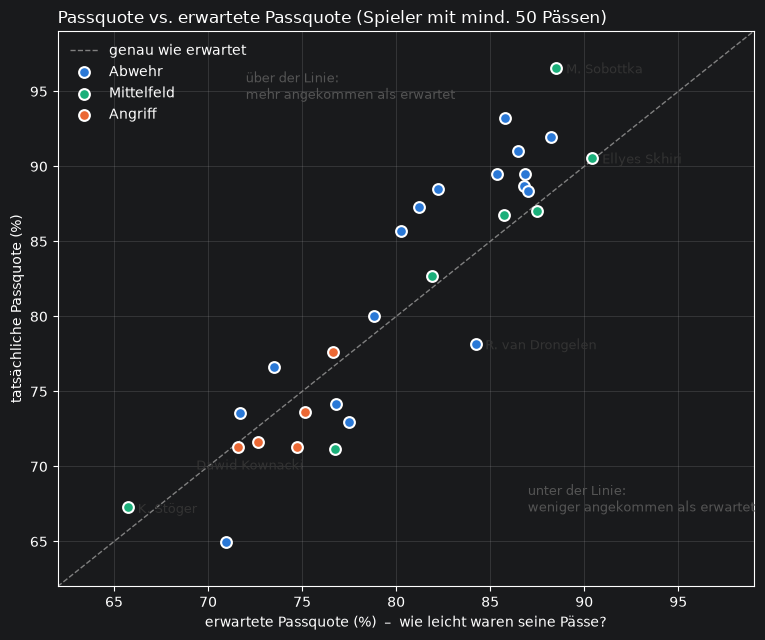

In [2]:
MANNSCHAFTSTEIL = {"Torwart": "Abwehr", "Innenverteidiger": "Abwehr", "Außenverteidiger": "Abwehr",
                   "Zentrales Mittelfeld": "Mittelfeld", "Flügel": "Angriff", "Zehner/Sturm": "Angriff"}
FARBE = {"Abwehr": "#2a78d6", "Mittelfeld": "#1baf7a", "Angriff": "#eb6834"}
# beschriftete Beispielspieler und wohin ihr Name geschrieben wird (Versatz in Punkten)
BEISPIELE = {"M. Sobottka": (7, -4), "Ellyes Skhiri": (7, -4), "K. Stöger": (7, -4),
             "Dawid Kownacki": (-30, -16), "R. van Drongelen": (7, -4)}

r = stamm["passquote"].corr(stamm["erwartete_quote"])
print(f"Korrelation zwischen Passquote und erwarteter Passquote: r = {r:.2f}")

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.plot([62, 99], [62, 99], ls="--", lw=1, color="grey", label="genau wie erwartet")
for teil, farbe in FARBE.items():
    g = stamm[stamm["hauptrolle"].map(MANNSCHAFTSTEIL) == teil]
    ax.scatter(g["erwartete_quote"], g["passquote"], s=60, color=farbe, label=teil,
               edgecolors="white", linewidths=1.5, zorder=3)
for _, s in stamm[stamm["player"].isin(BEISPIELE)].iterrows():
    ax.annotate(s["player"], (s["erwartete_quote"], s["passquote"]), xytext=BEISPIELE[s["player"]],
                textcoords="offset points", fontsize=9.5, color="#333333")
ax.text(72, 94.5, "über der Linie:\nmehr angekommen als erwartet", fontsize=9, color="#555555")
ax.text(87, 67, "unter der Linie:\nweniger angekommen als erwartet", fontsize=9, color="#555555")
ax.set_xlim(62, 99); ax.set_ylim(62, 99)
ax.set_xlabel("erwartete Passquote (%)  –  wie leicht waren seine Pässe?")
ax.set_ylabel("tatsächliche Passquote (%)")
ax.set_title("Passquote vs. erwartete Passquote (Spieler mit mind. 50 Pässen)", loc="left")
ax.grid(alpha=0.25)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

Die Punkte liegen fast auf einer Linie: Wer leichte Pässe spielt, hat eine hohe Quote. Die Passquote sortiert Spieler also vor allem nach Rolle und Spielweise (Abwehr rechts oben, Angriff links unten), kaum nach Passqualität.

**Fußballerische Probe:** Zwei zentrale Mittelfeldspieler mit fast gleicher Passzahl, aber völlig verschiedener Passquote. Was spielen sie für Pässe?

In [3]:
# Passprofil: Anteil hoher Bälle, Anteil Pässe nach vorn (höchstens 60° neben der Richtung Tor), mittlerer Abspielort
# Abspielort x: 0 = Mittellinie, negativ = eigene Hälfte, positiv = gegnerische Hälfte
d["hoher_ball"] = d["hoehe"] == "high"
d["nach_vorn"] = np.cos(np.radians(d["play_angle"])) > 0.5
profil = d.groupby("player").agg(hohe_baelle=("hoher_ball", "mean"), nach_vorn=("nach_vorn", "mean"),
                                 abspielort_x=("x", "mean"))
profil[["hohe_baelle", "nach_vorn"]] *= 100

print(f"Zum Vergleich, alle Pässe: {100 * d['hoher_ball'].mean():.0f} % hohe Bälle, "
      f"{100 * d['nach_vorn'].mean():.0f} % nach vorn")
stamm["rang_passquote"] = stamm["passquote"].rank(ascending=False).astype(int)
spalten = ["team", "paesse", "passquote", "rang_passquote", "erwartete_quote", "pue_100",
           "hohe_baelle", "nach_vorn", "abspielort_x"]
stamm.set_index("player").join(profil).loc[["Ellyes Skhiri", "K. Stöger", "M. Sobottka"], spalten].round(1)

Zum Vergleich, alle Pässe: 29 % hohe Bälle, 45 % nach vorn


,team,paesse,passquote,rang_passquote,erwartete_quote,pue_100,hohe_baelle,nach_vorn,abspielort_x
player,,,,,,,,,
Ellyes Skhiri,1. FC Köln,53,90.6,5,90.4,0.1,13.2,32.1,-8.7
K. Stöger,VfL Bochum 1848,55,67.3,28,65.7,1.5,45.5,54.5,13.5
M. Sobottka,Fortuna Düsseldorf,175,96.6,1,88.5,8.1,10.3,33.1,-0.2


- **Skhiri** (Köln): Passquote 91 %, Rang 5 von 29. Er spielt fast nur flache Pässe, meist in der eigenen Hälfte (13 % hohe Bälle, 32 % nach vorn), das Profil eines Absicherers vor der Abwehr. Das Modell erwartet 90 %: **genau im Soll** (+0,1).
- **Stöger** (Bochum): Passquote 67 %, Rang 28 von 29. Er spielt die schwersten Pässe aller 29 Spieler: 45 % hohe Bälle, 55 % nach vorn, meist in der gegnerischen Hälfte. Das Modell erwartet 66 %: **ebenfalls im Soll** (+1,5).
- Nach der Passquote wäre Stöger einer der schwächsten Passer. Das Modell sagt: Beide passen genau so gut wie erwartet, sie haben nur **andere Aufgaben**. Das Modell erkennt also die Spielweise und bewertet nur die Ausführung. Das ist fußballerisch plausibel.
- **Sobottka** (Düsseldorf) fällt aus der Reihe: 97 % angekommen bei erwarteten 89 % → **+8,1**, der höchste Wert. Er spielt ähnlich sichere Pässe wie Skhiri, bringt sie aber noch zuverlässiger an.

## 2. Rangliste – fair nur innerhalb der Rolle

Zuerst die PüE je Rolle (`zufall_100` = Schwankung allein durch Zufall, 1 Standardabweichung):

In [4]:
bilanz(d, "rolle").loc[ROLLEN, ["paesse", "pue_100", "zufall_100"]].round(1)

,paesse,pue_100,zufall_100
rolle,,,
Torwart,634,0.8,1.5
Innenverteidiger,1511,3.2,0.8
Außenverteidiger,1033,-0.3,1.1
Zentrales Mittelfeld,1140,0.3,1.0
Flügel,631,-2.2,1.5
Zehner/Sturm,715,-5.3,1.4


Innenverteidiger liegen bei +3,2, Zehner und Stürmer bei −5,3, beides weit mehr als der Zufall. Fußballerisch ist klar, warum: Ein Innenverteidiger spielt meist ohne Gegner im Nacken einen frei stehenden Mitspieler an. Ein Stürmer passt mit dem Rücken zum Tor, eng gedeckt, in engen Räumen. Das Zonenmodell kennt Ort, Richtung und Höhe, aber **keinen Gegnerdruck**. Es hält Stürmer-Pässe deshalb für leichter, als sie sind.

**Folge:** Spieler nur mit ihrer eigenen Rolle vergleichen. Dafür ziehen wir von jedem Spieler den Durchschnitt seiner Rolle ab (**PüE ggü. Rolle**). Das beantwortet die Frage eines Scouts: Passt dieser Mittelfeldspieler besser als andere Mittelfeldspieler?

In [5]:
rollen_schnitt = bilanz(d, "rolle")["pue_100"]                       # PüE pro 100 je Rolle
stamm["pue_ggue_rolle"] = stamm["pue_100"] - stamm["hauptrolle"].map(rollen_schnitt)

spalten = ["player", "team", "hauptrolle", "paesse", "passquote", "pue_100", "pue_ggue_rolle", "zufall_100"]
rangliste = stamm.sort_values("pue_ggue_rolle", ascending=False)[spalten].round(1)
pd.concat([rangliste.head(5), rangliste.tail(3)])                    # die besten 5 und die schwächsten 3

,player,team,hauptrolle,paesse,passquote,pue_100,pue_ggue_rolle,zufall_100
32,M. Sobottka,Fortuna Düsseldorf,Zentrales Mittelfeld,175,96.6,8.1,7.8,2.2
62,Benjamin Pavard,FC Bayern München,Außenverteidiger,55,87.3,6.0,6.4,4.5
91,Dawid Kownacki,Fortuna Düsseldorf,Zehner/Sturm,94,71.3,-0.3,5.0,4.0
60,Timo Hübers,1. FC Köln,Innenverteidiger,59,93.2,7.5,4.2,3.9
100,Shinta Appelkamp,Fortuna Düsseldorf,Zehner/Sturm,110,73.6,-1.5,3.8,3.6
42,Lukas Fröde,F.C. Hansa Rostock,Innenverteidiger,58,74.1,-2.7,-5.9,4.6
104,Exequiel Palacios,Bayer 04 Leverkusen,Zentrales Mittelfeld,52,71.2,-5.6,-5.9,4.8
73,R. van Drongelen,F.C. Hansa Rostock,Innenverteidiger,55,78.2,-6.0,-9.3,4.4


- **Sobottka** bleibt vorn: +7,8 gegenüber anderen zentralen Mittelfeldspielern.
- **Kownacki** springt nach vorn: Absolut liegt er im Soll (−0,3), für einen Stürmer passt er aber überdurchschnittlich sicher (+5,0). Ohne Rollenvergleich wäre das untergegangen.
- **van Drongelen** fällt ans Ende (−9,3): Als Innenverteidiger hat er leichte Pässe (erwartet 84 %), bringt aber nur 78 % an. Grundlage: ein Spiel, 55 Pässe.
- Die Zufallsschwankung (`zufall_100`) liegt bei ±2 bis ±5, also fast so groß wie die Unterschiede selbst.

(Mit den Tracking-Merkmalen aus Notebook 04, also Druck, Freiraum und Gegner im Passweg, schrumpft der Rolleneffekt: Zehner/Sturm −5,4 → −4,3; gerechnet nur auf den Pässen mit Tracking, daher −5,4 statt −5,3. Er verschwindet aber nicht.)

## 3. Wie belastbar ist das?

**Gering.** Die Kennzahl liefert gute Hinweise, aber noch keine Belege. Dafür gibt es drei Gründe:

- **Wenige Pässe, viel Zufall.** Die meisten Spieler haben nur 50 bis 100 Pässe. Die Spalte `zufall_100` zeigt, wie stark ihr Wert allein durch Glück und Pech schwankt: ±2 bis ±5 Pässe pro 100. Das ist etwa so groß wie die Unterschiede zwischen den Spielern. Am deutlichsten hebt sich Sobottka ab: +8,1 bei einer Schwankung von nur ±2,2, weil er mit 175 Pässen die größte Datenbasis der Spitzengruppe hat.
- **Wenige Spiele, viel Spielkontext.** Außer Düsseldorf (5 Spiele) ist jedes Team nur mit einem Spiel dabei. Die Werte von Pavard, Hübers oder van Drongelen beschreiben also ein einziges Spiel gegen einen bestimmten Gegner. Wie hoch hat der Gegner angelaufen? Lag das Team vorn und hat den Ball laufen lassen? Solche Einflüsse kann das Modell nicht von der Passqualität trennen.
- **Das Modell sieht keine Gegenspieler.** Es kennt Ort, Richtung, Höhe und Situation, aber nicht, wie eng ein Spieler gedeckt ist. Der Abzug des Rollenschnitts gleicht das nur grob aus: Auch innerhalb einer Rolle hat zum Beispiel ein Stürmer, der Bälle mit dem Rücken zum Tor festmachen muss, andere als einer, der in die Tiefe startet.

**Was dafür spricht:** Die xPass-Werte selbst sind sauber erzeugt. Jedes Spiel wurde von einem Modell vorhergesagt, das dieses Spiel nicht kannte, und das Modell trifft die Erfolgsquote in allen Zonen und Passarten gut (Notebook 02). Die Unsicherheit liegt also weniger im Modell als in der kleinen Datenmenge.

**Bewertung:** Sobottka bringt in diesen Daten klar mehr Pässe an als erwartet, auch im Vergleich mit seiner Rolle. Er ist damit ein **Kandidat, kein Beleg**. Für einen Verein heißt das: Nach 7 Spielen eignet sich die Kennzahl als Filter für das Video-Scouting („Wen schaue ich mir genauer an?“), nicht als Urteil über einen Spieler. Belastbar wird sie mit deutlich mehr Spielen (eher einer Hinrunde als 7 Spielen), mit Vergleichen nur innerhalb der Rolle und mit Gegnerdruck aus dem Tracking (Notebook 04).

## Fazit

| Frage | Ergebnis | Fußballerisch |
|---|---|---|
| Was misst PüE? | Die Ausführung, nicht das Risiko. Passquote und erwartete Quote korrelieren mit r = 0,92 | Stöger (67 %) und Skhiri (91 %) passen beide genau wie erwartet, sie spielen nur andere Pässe |
| Wer liegt vorn? | Sobottka +8,1 pro 100 (175 Pässe), auch innerhalb der Rolle vorn (+7,8) | Kandidat für einen überdurchschnittlich sicheren Passgeber im Zentrum |
| Rolle | Innenverteidiger +3,2, Zehner/Sturm −5,3 | Das Modell kennt keinen Gegnerdruck → nur innerhalb der Rolle vergleichen |
| Belastbarkeit | Gering: wenige Pässe je Spieler, meist nur ein Spiel je Team | Filter für das Video-Scouting, kein Urteil |